# 01. Análisis exploratorio de datos

**Proyecto:** Sistema inteligente de detección y clasificación de phishing híbrido (NLP y análisis de URL), Grupo 17.

Este notebook describe los datos con los que se entrenó el detector y documenta los hallazgos que
justifican las decisiones de preparación del notebook `02_preprocesamiento`. Trabaja sobre dos tablas:

| Tabla | Contenido | Generada por |
|---|---|---|
| `data/interim/emails_v0.parquet` | Todos los correos en inglés de las seis fuentes, ya defangeados, antes de cualquier exclusión | `notebooks/experimentos/02_eda_dqr` |
| `data/processed/emails_v1.parquet` | Dataset final en inglés, con particiones | `02_preprocesamiento` |
| `data/processed/emails_es_v2.parquet` | Correos en español nativos (SpaPhish, SpearPhishMX) y espejo traducido | `notebooks/experimentos/10_datos_es` y `10b` |

Preguntas que guían el análisis, derivadas de los tres riesgos del proyecto:

1. **Composición.** ¿Cada clase proviene de más de un corpus, o la clase coincide con la fuente?
2. **Calidad.** ¿Hay textos vacíos, duplicados o etiquetas en conflicto entre fuentes?
3. **URL.** ¿Qué proporción de correos tiene una URL utilizable por la rama URL?
4. **Tiempo e idioma.** ¿Las clases cubren los mismos años e idiomas, o hay confusores?
5. **Patrones.** ¿Qué variables y términos se asocian a cada clase?

Todo el texto se maneja defangeado (por ejemplo `hxxps[://]ejemplo[.]com`); ningún enlace se resuelve ni se visita.

In [1]:
# Rutas, semillas y módulos del proyecto. En Colab se monta Google Drive: el repositorio
# debe estar copiado en MyDrive/PI_G17/phishing-hibrido-g17 y los datos en MyDrive/PI_G17.
# Las variables de entorno G17_REPO y G17_BASE permiten usar otras ubicaciones.
import os
import sys
from pathlib import Path

try:
    from google.colab import drive

    drive.mount("/content/drive")
    RAIZ_POR_DEFECTO = "/content/drive/MyDrive/PI_G17/phishing-hibrido-g17"
except ImportError:
    RAIZ_POR_DEFECTO = str(Path.cwd().parent)

RAIZ = Path(os.environ.get("G17_REPO", RAIZ_POR_DEFECTO)).resolve()
if not (RAIZ / "src").is_dir():
    raise FileNotFoundError(f"No se encontró el repositorio en {RAIZ}; defina G17_REPO")
sys.path.insert(0, str(RAIZ))

from src.utils import cargar_config, configurar_logging, detectar_entorno, fijar_semillas, ruta_datos
from src.visualizacion import aplicar_estilo, guardar_figura

CONFIG = cargar_config(RAIZ / "config.yaml")
SEMILLA = CONFIG["semilla"]
fijar_semillas(SEMILLA)
configurar_logging("WARNING")
aplicar_estilo()

ENTORNO = detectar_entorno()
BASE = ruta_datos(CONFIG, ENTORNO)
PROCESADOS = BASE / CONFIG["rutas"]["datos_procesados"]
MODELOS = BASE / CONFIG["rutas"]["modelos"]
FIGURAS = RAIZ / "results/figures/01_exploracion"
METRICAS = RAIZ / "results/metrics"
FIGURAS.mkdir(parents=True, exist_ok=True)
METRICAS.mkdir(parents=True, exist_ok=True)
INTERMEDIOS = BASE / "data/interim"
EDA = BASE / "data/eda"
print(f"Entorno: {ENTORNO} | repositorio: {RAIZ} | datos: {BASE}")

Mounted at /content/drive
Entorno: colab | repositorio: /content/drive/MyDrive/PI_G17/phishing-hibrido-g17 | datos: /content/drive/MyDrive/PI_G17


In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.visualizacion import COLORES_CLASE, COLORES_SERIE, NOMBRES_CLASE, miles

CLASES = CONFIG["clases"]
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

## 1. Carga y descripción de las tablas

Se cargan solo las columnas necesarias; el texto completo se lee más adelante y únicamente del dataset final.

In [3]:
COLUMNAS_V0 = ["fuente", "grupo", "etiqueta_original", "clase", "anio", "idioma", "hash",
               "n_urls", "sin_url", "es_html", "len_plano"]
crudo = pd.read_parquet(INTERMEDIOS / "emails_v0.parquet", columns=COLUMNAS_V0)
final = pd.read_parquet(PROCESADOS / "emails_v1.parquet",
                        columns=["id", "grupo", "clase", "y", "anio", "n_urls", "sin_url", "es_html",
                                 "len_plano", "split"])
espanol = pd.read_parquet(PROCESADOS / "emails_es_v2.parquet",
                          columns=["id", "grupo", "clase", "split", "n_urls", "len_plano"])

print(f"Tabla intermedia (todas las fuentes): {miles(len(crudo))} correos, {crudo['grupo'].nunique()} corpus")
print(f"Dataset final en inglés:              {miles(len(final))} correos")
print(f"Dataset en español (v2):              {miles(len(espanol))} correos")

Tabla intermedia (todas las fuentes): 94.566 correos, 8 corpus
Dataset final en inglés:              54.684 correos
Dataset en español (v2):              55.130 correos


### Diccionario de variables

| Variable | Tipo | Descripción |
|---|---|---|
| `fuente`, `grupo` | categórica | Archivo y corpus de origen (por ejemplo `kaggle/CEAS_08` y `CEAS_08`) |
| `etiqueta_original` | entera | Etiqueta publicada por la fuente (0 o 1) |
| `clase` | categórica | Clase armonizada: legítimo, spam o phishing |
| `anio` | entera | Año del encabezado `Date`, si existe |
| `idioma` | categórica | Idioma detectado con `langdetect` (completo en las fuentes crudas, muestra en Kaggle) |
| `hash` | texto | SHA-1 del texto plano normalizado, para deduplicar |
| `n_urls`, `sin_url` | numérica, booleana | URL válidas extraídas del correo |
| `es_html` | booleana | El cuerpo contiene HTML |
| `len_plano` | entera | Longitud del texto plano en caracteres |

In [4]:
composicion = pd.crosstab(crudo["grupo"], crudo["clase"], margins=True, margins_name="Total")
composicion = composicion[[c for c in CLASES if c in composicion.columns] + ["Total"]]
composicion

clase,legitimo,spam,phishing,Total
grupo,,,,
CEAS_08,17312,21842,0,39154
Enron,15791,13976,0,29767
Ling,2401,458,0,2859
Nazario,0,0,1565,1565
Nigerian_Fraud,0,0,3332,3332
SpamAssasin,4091,1718,0,5809
nazario_anual,0,0,3466,3466
phishing_pot,0,0,8614,8614
Total,39595,37994,16977,94566


## 2. Estadísticas descriptivas y datos faltantes

In [5]:
descriptivas = (crudo.groupby("clase")[["len_plano", "n_urls"]]
                .describe(percentiles=[0.5, 0.99]).round(1))
descriptivas

len_plano                                                       n_urls                                   
             count    mean      std   min     50%       99%        max    count mean   std  min  50%   99%     max
clase                                                                                                             
legitimo   39595.0  2123.7   5200.7  16.0  1090.0   17780.8   298929.0  39595.0  1.5  17.1  0.0  0.0  19.0  3134.0
phishing   16977.0  7518.7  60462.3   0.0   966.0  429081.1  4549430.0  16977.0  4.1   8.6  0.0  2.0  34.0   457.0
spam       37994.0  1136.4   2665.3   3.0   425.0    8368.3   230889.0  37994.0  2.3   6.5  0.0  0.0  24.0   188.0

In [6]:
faltantes = pd.DataFrame({
    "anio_faltante_pct": crudo.groupby("grupo")["anio"].apply(lambda s: 100 * s.isna().mean()),
    "idioma_medido_pct": crudo.groupby("grupo")["idioma"].apply(lambda s: 100 * s.notna().mean()),
    "texto_casi_vacio_pct": crudo.groupby("grupo")["len_plano"].apply(lambda s: 100 * (s < 20).mean()),
}).round(1)
faltantes

,anio_faltante_pct,idioma_medido_pct,texto_casi_vacio_pct
grupo,,,
CEAS_08,0.1,0.0,0.0
Enron,100.0,0.0,0.0
Ling,100.0,0.0,0.0
Nazario,0.1,0.0,0.0
Nigerian_Fraud,14.9,0.0,0.0
SpamAssasin,1.5,0.0,0.0
nazario_anual,1.9,100.0,0.2
phishing_pot,0.1,100.0,0.2


La fecha falta por completo en Enron y Ling y en el 15 % de Nigerian Fraud. En la tabla intermedia el idioma
solo se guardó para las fuentes crudas (phishing_pot y Nazario anual), donde se midió en el 100 % de los
correos. En los corpus de Kaggle se midió sobre una muestra de 1.500 correos por corpus en el reporte de
calidad de datos: entre el 95,8 % y el 99,6 % estaba en inglés. Los textos casi vacíos (menos de 20 caracteres)
son 39 y se excluyen en la preparación.

## 3. Composición: ¿la clase coincide con la fuente?

**Figura 1.** Número de correos por corpus y clase. Si una clase viniera de un único corpus, el modelo podría
aprender el estilo de la fuente en lugar de la señal de phishing (riesgo 1 del proyecto).

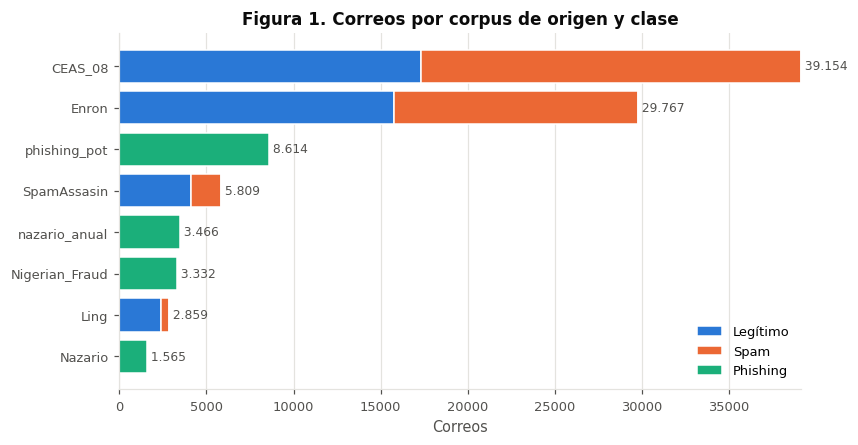

Corpus de origen por clase: {'legitimo': 4, 'spam': 4, 'phishing': 4}


In [7]:
orden = composicion.drop(index="Total").sort_values("Total").index
figura, eje = plt.subplots(figsize=(8, 4.2))
izquierda = np.zeros(len(orden))
for clase in CLASES:
    valores = composicion.loc[orden, clase].to_numpy() if clase in composicion else np.zeros(len(orden))
    eje.barh(orden, valores, left=izquierda, color=COLORES_CLASE[clase], label=NOMBRES_CLASE[clase],
             edgecolor="white", linewidth=1)
    izquierda += valores
for posicion, total in enumerate(composicion.loc[orden, "Total"]):
    eje.text(total, posicion, f" {miles(total)}", va="center", fontsize=8, color="#52514e")
eje.set_xlabel("Correos")
eje.set_title("Figura 1. Correos por corpus de origen y clase")
eje.legend(loc="lower right")
eje.grid(axis="y", visible=False)
guardar_figura(figura, FIGURAS / "fig01_clase_por_corpus.png")
plt.show()

origenes = (composicion.drop(index="Total")[CLASES] > 0).sum()
print("Corpus de origen por clase:", origenes.to_dict())

Cada corpus aporta una sola clase o el par legítimo y spam (CEAS_08, Enron, Ling y SpamAssassin). La clase
phishing proviene siempre de corpus distintos a los de legítimo y spam. Por eso:

* se exige que cada clase tenga al menos dos corpus de origen;
* se evalúa con pliegues en los que un corpus completo queda fuera del entrenamiento (`loso_<corpus>`);
* se mide si un clasificador puede predecir el corpus a partir del texto (sección 11).

## 4. Longitud del texto y valores atípicos

**Figura 2.** Distribución de la longitud del texto plano por clase, en escala logarítmica.

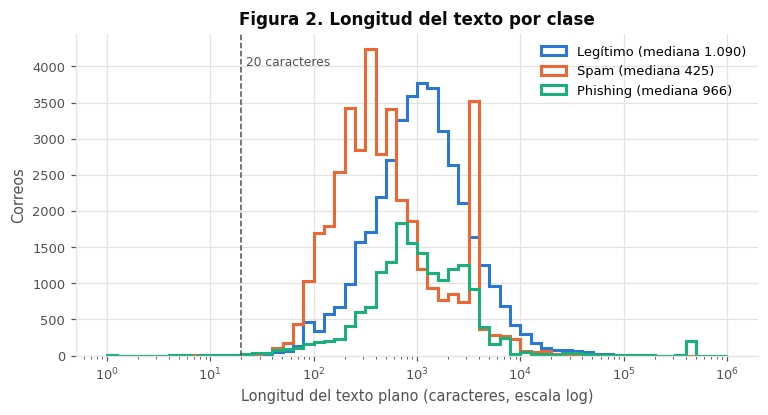

Percentil 99: 15.489 caracteres; correos por encima: 945
Atípicos por clase (%): {'legitimo': 48.9, 'phishing': 38.9, 'spam': 12.2}


In [8]:
figura, eje = plt.subplots(figsize=(8, 3.8))
bordes = np.logspace(0, 6, 61)
for clase in CLASES:
    longitudes = crudo.loc[crudo["clase"] == clase, "len_plano"].clip(lower=1)
    eje.hist(longitudes, bins=bordes, histtype="step", linewidth=2, color=COLORES_CLASE[clase],
             label=f"{NOMBRES_CLASE[clase]} (mediana {miles(int(longitudes.median()))})")
eje.set_xscale("log")
eje.axvline(20, color="#52514e", linestyle="--", linewidth=1)
eje.text(22, eje.get_ylim()[1] * 0.9, "20 caracteres", fontsize=8, color="#52514e")
eje.set_xlabel("Longitud del texto plano (caracteres, escala log)")
eje.set_ylabel("Correos")
eje.set_title("Figura 2. Longitud del texto por clase")
eje.legend()
guardar_figura(figura, FIGURAS / "fig02_longitud_por_clase.png")
plt.show()

p99 = crudo["len_plano"].quantile(0.99)
atipicos = crudo["len_plano"] > p99
print(f"Percentil 99: {miles(round(p99))} caracteres; correos por encima: {miles(int(atipicos.sum()))}")
print("Atípicos por clase (%):", (100 * crudo.loc[atipicos, "clase"].value_counts(normalize=True)).round(1).to_dict())

Las longitudes abarcan seis órdenes de magnitud y las medianas difieren por clase (spam, 425 caracteres;
phishing, 966; legítimo, 1.090). Por encima del percentil 99 (unos 15.500 caracteres) hay 945 correos, sobre
todo legítimos y de phishing; se conservan porque son correos reales, y el texto se trunca de forma declarada en
la entrada de los modelos (5.000 caracteres para TF-IDF y 256 tokens para DistilBERT).

## 5. Presencia de URL

**Figura 3.** Porcentaje de correos con al menos una URL válida por corpus, y número de URL por correo según la clase.
La rama URL solo aporta información cuando el correo tiene una URL analizable (riesgo 2).

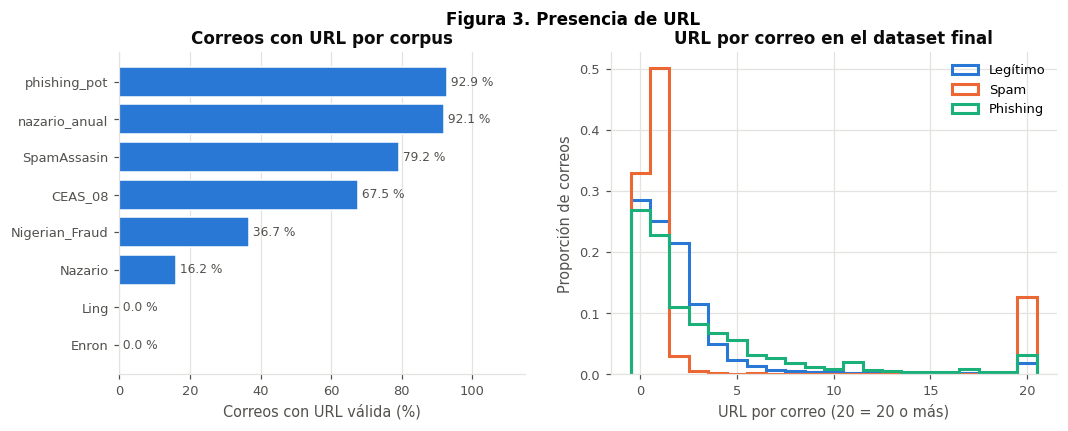

Dataset final, correos con URL por clase (%): {'legitimo': 71.5, 'phishing': 73.1, 'spam': 67.0}


In [9]:
con_url = (100 * (1 - crudo.groupby("grupo")["sin_url"].mean())).sort_values()
figura, (eje_a, eje_b) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.1]})
eje_a.barh(con_url.index, con_url.values, color=COLORES_SERIE[0], edgecolor="white")
for posicion, valor in enumerate(con_url.values):
    eje_a.text(valor, posicion, f" {valor:.1f} %", va="center", fontsize=8, color="#52514e")
eje_a.set_xlim(0, 115)
eje_a.set_xlabel("Correos con URL válida (%)")
eje_a.set_title("Correos con URL por corpus")
eje_a.grid(axis="y", visible=False)

bordes = np.arange(0, 22) - 0.5
for clase in CLASES:
    n_urls = final.loc[final["clase"] == clase, "n_urls"].clip(upper=20)
    eje_b.hist(n_urls, bins=bordes, histtype="step", linewidth=2, density=True,
               color=COLORES_CLASE[clase], label=NOMBRES_CLASE[clase])
eje_b.set_xlabel("URL por correo (20 = 20 o más)")
eje_b.set_ylabel("Proporción de correos")
eje_b.set_title("URL por correo en el dataset final")
eje_b.legend()
figura.suptitle("Figura 3. Presencia de URL", fontweight="bold", fontsize=11)
guardar_figura(figura, FIGURAS / "fig03_presencia_url.png")
plt.show()

pct_url_final = (100 * (1 - final.groupby("clase")["sin_url"].mean())).round(1)
print("Dataset final, correos con URL por clase (%):", pct_url_final.to_dict())

Enron y Ling contienen la cadena `http` en parte de sus textos, pero ninguna URL válida: el texto viene
tokenizado y las URL quedaron rotas. Además de no aportar a la rama URL, ese formato distinto permitiría al
modelo reconocer el corpus. En el dataset final, alrededor de 7 de cada 10 correos de cada clase tiene URL,
por lo que la rama URL es aplicable; para los correos sin URL se usa un valor neutro y el indicador `sin_url`.

## 6. Cobertura temporal

**Figura 4.** Año del encabezado `Date` por clase. Si las clases cubren periodos distintos, el año (o
expresiones ligadas a él) se convierte en un atajo para el modelo.

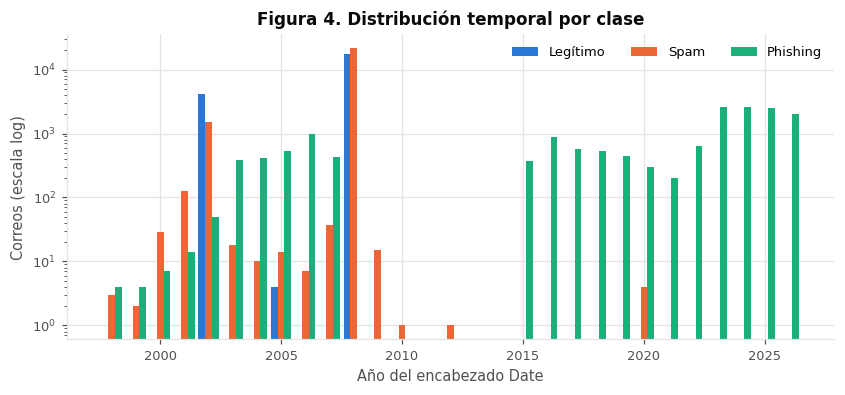

,count,min,50%,max
clase,,,,
legitimo,21402,2002,2008,2008
phishing,16408,1998,2023,2026
spam,23447,1998,2008,2020


In [10]:
anios = crudo.dropna(subset=["anio"]).astype({"anio": int})
anios = anios[anios["anio"].between(1998, 2026)]
tabla_anios = pd.crosstab(anios["anio"], anios["clase"]).reindex(columns=CLASES, fill_value=0)
figura, eje = plt.subplots(figsize=(9, 3.6))
ancho = 0.28
for k, clase in enumerate(CLASES):
    eje.bar(tabla_anios.index + (k - 1) * ancho, tabla_anios[clase], width=ancho,
            color=COLORES_CLASE[clase], label=NOMBRES_CLASE[clase])
eje.set_yscale("log")
eje.set_xlabel("Año del encabezado Date")
eje.set_ylabel("Correos (escala log)")
eje.set_title("Figura 4. Distribución temporal por clase")
eje.legend(ncols=3)
guardar_figura(figura, FIGURAS / "fig04_anio_por_clase.png")
plt.show()

rango = anios.groupby("clase")["anio"].describe()[["count", "min", "50%", "max"]].astype(int)
rango

En el reporte de calidad de datos, las medianas de legítimo y spam son 2002 (SpamAssassin) y 2008 (CEAS_08),
mientras que las del phishing van de 2018 a 2024, con la excepción de Nigerian Fraud (2006). Para que el modelo
no aprenda el año, los años de 1980 a 2029 se reemplazan por el marcador `__anio__` en el
texto de entrada, y se reserva un pliegue temporal (phishing desde 2025 fuera del entrenamiento).

## 7. Idioma

**Figura 5.** Idiomas detectados en los corpus donde se midió el idioma.

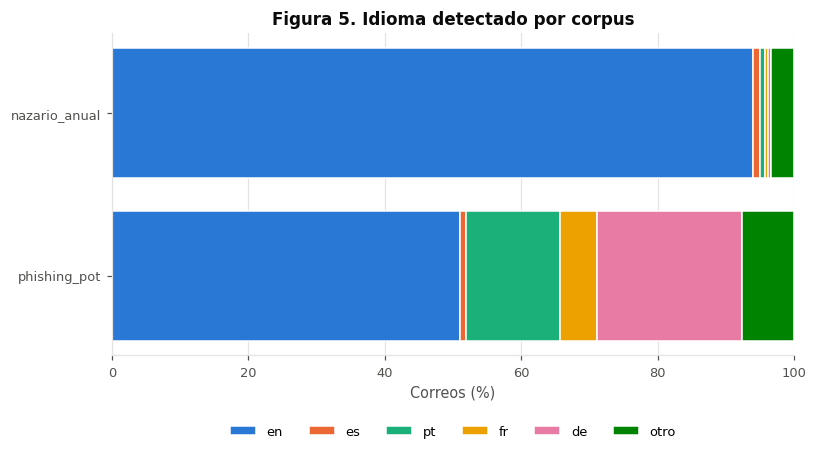

idioma_grupo,en,es,pt,fr,de,otro
grupo,,,,,,
phishing_pot,51.1,0.8,13.8,5.4,21.3,7.6
nazario_anual,94.0,1.0,0.8,0.5,0.5,3.3


In [11]:
medidos = crudo.dropna(subset=["idioma"])
principales = ["en", "es", "pt", "fr", "de"]
medidos = medidos.assign(idioma_grupo=np.where(medidos["idioma"].isin(principales), medidos["idioma"], "otro"))
idiomas = (100 * pd.crosstab(medidos["grupo"], medidos["idioma_grupo"], normalize="index"))
idiomas = idiomas[[c for c in principales + ["otro"] if c in idiomas.columns]].sort_values("en")
figura, eje = plt.subplots(figsize=(8, 3.8))
izquierda = np.zeros(len(idiomas))
for k, idioma in enumerate(idiomas.columns):
    eje.barh(idiomas.index, idiomas[idioma], left=izquierda, color=COLORES_SERIE[k % len(COLORES_SERIE)],
             label=idioma, edgecolor="white", linewidth=1)
    izquierda += idiomas[idioma].to_numpy()
eje.set_xlabel("Correos (%)")
eje.set_xlim(0, 100)
eje.set_title("Figura 5. Idioma detectado por corpus")
eje.legend(ncols=len(idiomas.columns), loc="upper center", bbox_to_anchor=(0.5, -0.18))
eje.grid(axis="y", visible=False)
guardar_figura(figura, FIGURAS / "fig05_idioma_por_corpus.png")
plt.show()
idiomas.round(1)

Cerca de la mitad de phishing_pot no está en inglés. Para el modelo inglés se conservan solo los correos en
inglés de las fuentes crudas; el español se trata con una ruta propia (SpaPhish y SpearPhishMX) y cualquier
otro idioma se marca para revisión manual.

## 8. Duplicados y conflictos de etiqueta

**Figura 6.** Correos duplicados dentro de cada corpus y huellas repetidas entre corpus.

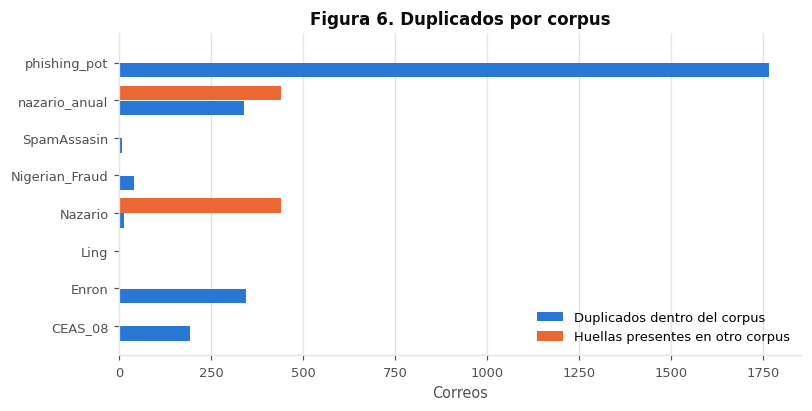

{'duplicados_dentro_del_corpus': 2702,
 'huellas_en_varios_corpus': 441,
 'huellas_con_clases_en_conflicto': 0,
 'textos_casi_vacios': 39}

In [12]:
duplicados_intra = crudo.duplicated(["grupo", "hash"]).groupby(crudo["grupo"]).sum()
corpus_por_hash = crudo.groupby("hash")["grupo"].nunique()
clases_por_hash = crudo.groupby("hash")["clase"].nunique()
en_varios = crudo[crudo["hash"].isin(corpus_por_hash[corpus_por_hash > 1].index)]
entre_corpus = en_varios.groupby("grupo")["hash"].nunique().reindex(duplicados_intra.index, fill_value=0)

figura, eje = plt.subplots(figsize=(8, 3.8))
posiciones = np.arange(len(duplicados_intra))
eje.barh(posiciones - 0.2, duplicados_intra.values, height=0.38, color=COLORES_SERIE[0],
         label="Duplicados dentro del corpus")
eje.barh(posiciones + 0.2, entre_corpus.values, height=0.38, color=COLORES_SERIE[1],
         label="Huellas presentes en otro corpus")
eje.set_yticks(posiciones, duplicados_intra.index)
eje.set_xlabel("Correos")
eje.set_title("Figura 6. Duplicados por corpus")
eje.legend(loc="lower right")
eje.grid(axis="y", visible=False)
guardar_figura(figura, FIGURAS / "fig06_duplicados.png")
plt.show()

calidad = {
    "duplicados_dentro_del_corpus": int(duplicados_intra.sum()),
    "huellas_en_varios_corpus": int((corpus_por_hash > 1).sum()),
    "huellas_con_clases_en_conflicto": int((clases_por_hash > 1).sum()),
    "textos_casi_vacios": int((crudo["len_plano"] < 20).sum()),
}
calidad

Los duplicados se eliminan antes de particionar para que un mismo correo no aparezca en entrenamiento y en
prueba (fuga de datos). Las huellas compartidas entre Nazario (CSV) y Nazario anual confirman que son el
mismo material; se conserva la versión cruda, que mantiene los enlaces.

## 9. Correlaciones entre variables y clase

**Figura 7.** Correlación de Spearman entre las variables numéricas del correo y el indicador de cada clase,
en el dataset final.

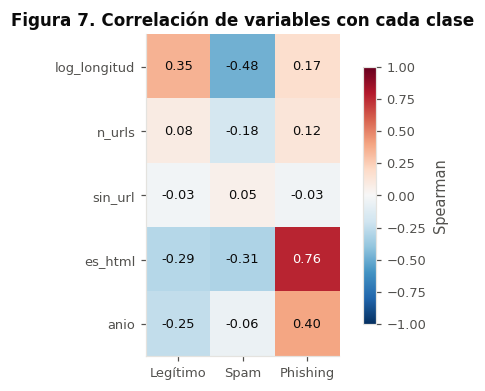

,es_legitimo,es_spam,es_phishing
log_longitud,0.349,-0.477,0.170
n_urls,0.082,-0.178,0.124
sin_url,-0.028,0.054,-0.033
es_html,-0.286,-0.309,0.759
anio,-0.245,-0.061,0.396


In [13]:
variables = pd.DataFrame({
    "log_longitud": np.log1p(final["len_plano"]),
    "n_urls": final["n_urls"],
    "sin_url": final["sin_url"].astype(int),
    "es_html": final["es_html"].astype(int),
    "anio": final["anio"],
})
for clase in CLASES:
    variables[f"es_{clase}"] = (final["clase"] == clase).astype(int)
correlacion = variables.corr(method="spearman").loc[
    ["log_longitud", "n_urls", "sin_url", "es_html", "anio"], [f"es_{c}" for c in CLASES]]

figura, eje = plt.subplots(figsize=(5.6, 3.8))
imagen = eje.imshow(correlacion.values, cmap="RdBu_r", vmin=-1, vmax=1)
eje.set_xticks(range(len(CLASES)), [NOMBRES_CLASE[c] for c in CLASES])
eje.set_yticks(range(len(correlacion)), correlacion.index)
for i in range(correlacion.shape[0]):
    for j in range(correlacion.shape[1]):
        valor = correlacion.iat[i, j]
        if not np.isnan(valor):
            eje.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=8.5,
                     color="white" if abs(valor) > 0.5 else "#0b0b0b")
eje.grid(False)
figura.colorbar(imagen, ax=eje, shrink=0.8, label="Spearman")
eje.set_title("Figura 7. Correlación de variables con cada clase")
guardar_figura(figura, FIGURAS / "fig07_correlaciones.png")
plt.show()
correlacion.round(3)

La variable más asociada al phishing es el formato HTML (0,76). El reporte de calidad lo explica por el formato
de origen: el atributo `href` aparece en cerca del 90 % de los correos de phishing_pot y Nazario anual (archivos
.eml y mbox crudos) y en menos del 1 % de los CSV de Kaggle. Le siguen el año (0,40) y,
para el spam, la longitud corta (-0,48). Son atajos que el modelo podría aprender en lugar del contenido, por
eso ninguno entra directamente al modelo de texto: `texto_para_modelo` elimina el HTML y enmascara los años.
La presencia y el número de URL, con correlaciones bajas (0,18 o menos en valor absoluto), sí llegan al
meta-clasificador a través de la rama URL.

## 10. Términos asociados a cada clase

**Figura 8.** Términos con mayor estadístico chi-cuadrado para cada clase, calculado solo sobre la partición
de entrenamiento y una muestra estratificada (para acotar el costo). Los marcadores como `__url__` son
sustituciones del pipeline.

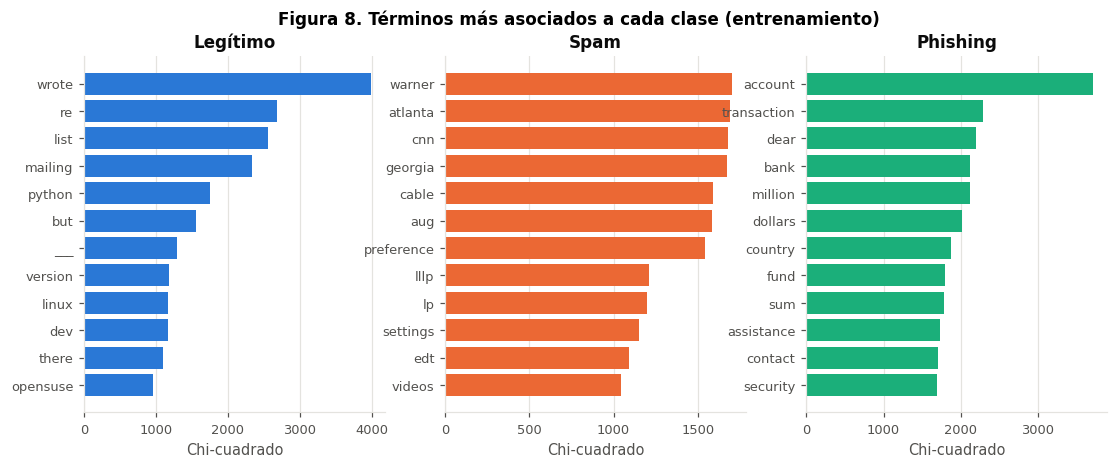

In [14]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2

entrenamiento = pd.read_parquet(PROCESADOS / "emails_v1.parquet", columns=["clase", "split", "texto_modelo"])
entrenamiento = entrenamiento[entrenamiento["split"] == "train"]
muestra = (entrenamiento.sample(frac=1, random_state=SEMILLA).groupby("clase").head(5000))
vectorizador = CountVectorizer(min_df=20, max_df=0.5, token_pattern=r"(?u)\b[a-z_][a-z_]+\b",
                               lowercase=True, binary=True)
matriz = vectorizador.fit_transform(muestra["texto_modelo"].str[:5000])
vocabulario = np.array(vectorizador.get_feature_names_out())

figura, ejes = plt.subplots(1, 3, figsize=(12, 4.2))
terminos = {}
for eje, clase in zip(ejes, CLASES, strict=True):
    puntaje, _ = chi2(matriz, (muestra["clase"] == clase).to_numpy())
    positivos = np.asarray(matriz[(muestra["clase"] == clase).to_numpy()].mean(axis=0)).ravel()
    resto = np.asarray(matriz[(muestra["clase"] != clase).to_numpy()].mean(axis=0)).ravel()
    candidatos = np.where(positivos > resto)[0]
    mejores = candidatos[np.argsort(puntaje[candidatos])[::-1][:12]][::-1]
    terminos[clase] = vocabulario[mejores][::-1].tolist()
    eje.barh(vocabulario[mejores], puntaje[mejores], color=COLORES_CLASE[clase])
    eje.set_title(NOMBRES_CLASE[clase], color="#0b0b0b")
    eje.set_xlabel("Chi-cuadrado")
    eje.grid(axis="y", visible=False)
figura.suptitle("Figura 8. Términos más asociados a cada clase (entrenamiento)", fontweight="bold", fontsize=11)
guardar_figura(figura, FIGURAS / "fig08_terminos_por_clase.png")
plt.show()
del entrenamiento, muestra, matriz

Los términos describen el tipo de mensaje de cada corpus más que una regla general:

* **Legítimo:** vocabulario de listas de correo técnicas (*wrote*, *re*, *list*, *mailing*, *python*, *linux*).
* **Spam:** términos de pie de boletín (*cnn*, *atlanta*, *georgia*, *warner*, *cable*, *preference*,
  *settings*), lo que sugiere campañas masivas que repiten la misma plantilla dentro de CEAS_08.
* **Phishing:** vocabulario de fraude de pago anticipado (*transaction*, *million*, *dollars*, *fund*,
  *country*, *assistance*) junto con el de suplantación de cuentas (*account*, *bank*, *security*).

Es una señal de que el modelo puede apoyarse en el estilo de cada fuente. Se controla de dos formas: la sonda
de fuga de `02_preprocesamiento` busca términos que nombren la fuente, y los pliegues fuera de distribución
miden el desempeño cuando un corpus completo no se vio en el entrenamiento.

## 11. Prueba de artefacto de fuente

El reporte de calidad de datos (`data/eda/dqr_v1.json`) entrenó clasificadores auxiliares para medir cuánto se
puede predecir la fuente o la clase con información que no debería ser decisiva.

In [15]:
ruta_dqr = EDA / "dqr_v1.json"
if ruta_dqr.exists():
    dqr = json.loads(ruta_dqr.read_text(encoding="utf-8"))
    artefactos = pd.Series(dqr["Q6_artefactos_f1"], name="F1 macro")
else:
    dqr, artefactos = None, pd.Series(dtype=float, name="F1 macro")
    print("No se encontró dqr_v1.json; se omite esta sección")
artefactos

,F1 macro
n_muestra,15565.000
f1_predecir_GRUPO_con_texto,0.811
f1_predecir_GRUPO_de_phishing_con_texto,0.715
f1_predecir_CLASE_solo_metadatos,0.631
f1_predecir_CLASE_con_texto (referencia),0.959


Un clasificador TF-IDF predice el corpus a partir del texto con F1 macro de 0,81: cada fuente tiene un estilo
reconocible. Con solo metadatos (longitud, URL, HTML, longitud del asunto) la clase se predice con F1 de 0,63.
Por eso las métricas de la partición aleatoria se complementan con los pliegues fuera de distribución, que
miden si el detector reconoce phishing de un corpus que nunca vio.

## 12. Datos en español

**Figura 9.** Composición del dataset en español. Las fuentes nativas son SpaPhish y SpearPhishMX; los grupos
`traducido_*` son el espejo del corpus inglés traducido con OPUS-MT, que solo se usa para entrenar.

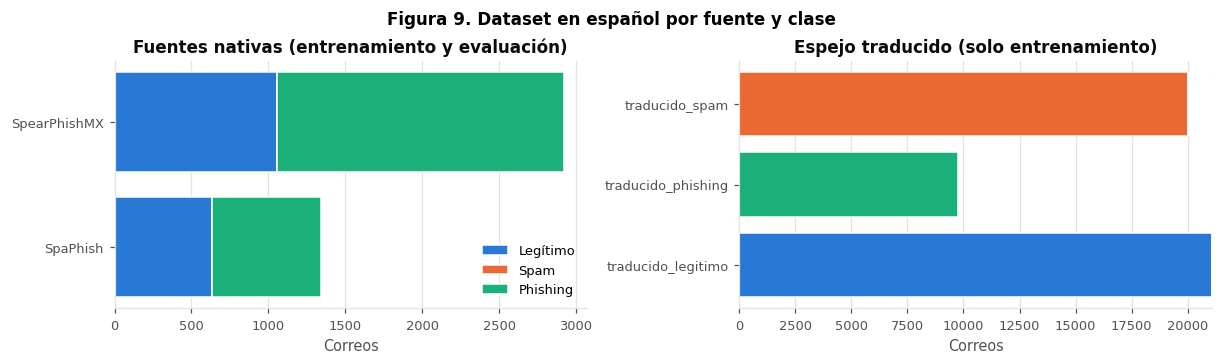

clase,legitimo,spam,phishing,Total
grupo,,,,
SpaPhish,632,0,711,1343
SpearPhishMX,1059,0,1866,2925
traducido_legitimo,21083,0,0,21083
traducido_phishing,0,0,9753,9753
traducido_spam,0,20026,0,20026


In [16]:
composicion_es = pd.crosstab(espanol["grupo"], espanol["clase"]).reindex(columns=CLASES, fill_value=0)
nativos = composicion_es.loc[~composicion_es.index.str.startswith("traducido_")]
traducidos = composicion_es.loc[composicion_es.index.str.startswith("traducido_")]
figura, ejes = plt.subplots(1, 2, figsize=(11, 3.2), layout="constrained")
for eje, tabla, titulo in ((ejes[0], nativos, "Fuentes nativas (entrenamiento y evaluación)"),
                           (ejes[1], traducidos, "Espejo traducido (solo entrenamiento)")):
    izquierda = np.zeros(len(tabla))
    for clase in CLASES:
        eje.barh(tabla.index, tabla[clase], left=izquierda, color=COLORES_CLASE[clase],
                 label=NOMBRES_CLASE[clase], edgecolor="white", linewidth=1)
        izquierda += tabla[clase].to_numpy()
    eje.set_xlabel("Correos")
    eje.set_title(titulo)
    eje.grid(axis="y", visible=False)
ejes[0].legend(loc="lower right")
figura.suptitle("Figura 9. Dataset en español por fuente y clase", fontweight="bold", fontsize=11)
guardar_figura(figura, FIGURAS / "fig09_espanol.png")
plt.show()
composicion_es.assign(Total=composicion_es.sum(axis=1))

No existe spam nativo en español, de modo que la ruta española es de hecho binaria (phishing frente a no
phishing) y su meta-clasificador se entrena así.

## 13. Balance de clases del dataset final

In [17]:
balance = pd.crosstab(final["split"], final["clase"]).reindex(columns=CLASES).loc[["train", "val", "test"]]
balance["phishing_pct"] = (100 * balance["phishing"] / balance[CLASES].sum(axis=1)).round(1)
balance

clase,legitimo,spam,phishing,phishing_pct
split,,,,
train,14965,16370,6943,18.1
val,3207,3508,1488,18.1
test,3207,3508,1488,18.1


El phishing representa cerca del 18 % de cada partición. El desbalance moderado se maneja con pesos de clase
(`class_weight="balanced"` en la regresión logística y pesos en la pérdida de DistilBERT) y con un umbral de
decisión fijado por la tasa de falsos positivos, no por exactitud.

## 14. Conclusiones y decisiones

| Hallazgo | Evidencia | Decisión (aplicada en `02_preprocesamiento`) |
|---|---|---|
| La clase está ligada al corpus | Figura 1, sección 11 | Dos corpus por clase como mínimo y pliegues fuera de distribución |
| Enron y Ling tienen URL destruidas y formato distinto | Figura 3 | Se excluyen del dataset inglés |
| Nazario CSV duplica a Nazario anual y perdió los enlaces | Figuras 3 y 6 | Se usa la versión cruda |
| El año separa las clases | Figuras 4 y 7 | Marcador `__anio__` y pliegue temporal |
| phishing_pot es multilingüe | Figura 5 | Filtro de idioma inglés en las fuentes crudas; ruta española aparte |
| Hay duplicados dentro y entre corpus | Figura 6 | Deduplicación por huella antes de particionar |
| El HTML y la longitud se asocian a la clase | Figura 7 | El texto de modelo elimina el HTML; la longitud no es variable del modelo |
| Los términos reflejan el estilo de cada corpus | Figura 8, sección 11 | Sonda de fuga y evaluación con un corpus fuera |
| Desbalance moderado | Sección 13 | Pesos de clase y umbral por tasa de falsos positivos |

In [18]:
resumen = {
    "n_correos_tabla_intermedia": int(len(crudo)),
    "n_correos_dataset_final": int(len(final)),
    "n_correos_espanol_v2": int(len(espanol)),
    "corpus_por_clase": origenes.to_dict(),
    "pct_con_url_final": pct_url_final.to_dict(),
    "calidad": calidad,
    "rango_anios": rango.to_dict(orient="index"),
    "terminos_chi2": terminos,
    "balance_final": balance.to_dict(orient="index"),
    "figuras": sorted(p.name for p in FIGURAS.glob("*.png")),
}
(METRICAS / "eda_resumen.json").write_text(json.dumps(resumen, indent=1, ensure_ascii=False, default=str),
                                           encoding="utf-8")
print(json.dumps({k: resumen[k] for k in ("n_correos_tabla_intermedia", "n_correos_dataset_final",
                                          "corpus_por_clase", "calidad")}, indent=1, ensure_ascii=False))

{
 "n_correos_tabla_intermedia": 94566,
 "n_correos_dataset_final": 54684,
 "corpus_por_clase": {
  "legitimo": 4,
  "spam": 4,
  "phishing": 4
 },
 "calidad": {
  "duplicados_dentro_del_corpus": 2702,
  "huellas_en_varios_corpus": 441,
  "huellas_con_clases_en_conflicto": 0,
  "textos_casi_vacios": 39
 }
}
